# Анализ продаж розничного магазина
*Retail sales analysis: data quality, KPIs, sales slices and customer segmentation*

**Задача:** оценить качество данных о продажах, посчитать ключевые показатели, найти закономерности по месяцам, категориям и дням недели, сегментировать покупателей и подготовить данные для BI-дашборда.

**Данные:** `scanner_data.csv` — транзакции розничного магазина за 2016 год: 131 706 строк, 22 625 покупателей, 187 товарных категорий.

**Инструменты:** `pandas`, `matplotlib`, `scikit-learn` (MiniBatchKMeans, silhouette score), Yandex DataLens.

> Учебный проект по курсу бизнес-информатики (МТУСИ). В методичке анализ предлагалось делать в Loginom, здесь все этапы реализованы на Python.


## 1. Загрузка библиотек и исходного файла

Положите `scanner_data.csv` в папку `data/`. В Google Colab при отсутствии файла появится окно загрузки.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from threadpoolctl import threadpool_limits

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

DATA_FILE = 'scanner_data.csv'

possible_paths = [
    Path('data') / DATA_FILE,
    Path(DATA_FILE),
    Path('/content') / DATA_FILE,
    Path('/mnt/data') / DATA_FILE
]
data_path = next((p for p in possible_paths if p.exists()), None)

if data_path is None:
    from google.colab import files
    uploaded = files.upload()
    data_path = Path(DATA_FILE)

print(f'Файл для анализа: {data_path}')

Файл для анализа: scanner_data.csv


In [2]:
df_raw = pd.read_csv(data_path)

print(f'Количество строк: {df_raw.shape[0]:,}')
print(f'Количество столбцов: {df_raw.shape[1]}')
display(df_raw.head())

Количество строк: 131,706
Количество столбцов: 8


,Unnamed: 0,Date,Customer_ID,Transaction_ID,SKU_Category,SKU,Quantity,Sales_Amount
0,1,02/01/2016,2547,1,X52,0EM7L,1.00,3.13
1,2,02/01/2016,822,2,2ML,68BRQ,1.00,5.46
2,3,02/01/2016,3686,3,0H2,CZUZX,1.00,6.35
3,4,02/01/2016,3719,4,0H2,549KK,1.00,5.59
4,5,02/01/2016,9200,5,0H2,K8EHH,1.00,6.88


## 2. Оценка качества исходных данных

На данном этапе проверяются:
- структура и типы полей;
- наличие пропусков;
- наличие полностью дублирующихся строк;
- число уникальных значений;
- технические столбцы, не несущие аналитической ценности.


In [3]:
quality_raw = pd.DataFrame({
    'Тип данных': df_raw.dtypes.astype(str),
    'Пропуски': df_raw.isna().sum(),
    'Доля пропусков, %': (df_raw.isna().mean() * 100).round(3),
    'Уникальные значения': df_raw.nunique(dropna=True)
})

display(quality_raw)
print(f'Полностью дублирующиеся строки: {df_raw.duplicated().sum():,}')

,Тип данных,Пропуски,"Доля пропусков, %",Уникальные значения
Unnamed: 0,int64,0,0.00,131706
Date,object,0,0.00,363
Customer_ID,int64,0,0.00,22625
Transaction_ID,int64,0,0.00,64682
SKU_Category,object,0,0.00,187
SKU,object,0,0.00,5242
Quantity,float64,0,0.00,83
Sales_Amount,float64,0,0.00,3233


Полностью дублирующиеся строки: 0


In [4]:
technical_columns = [col for col in df_raw.columns if col.lower().startswith('unnamed')]
print('Технические столбцы, подлежащие исключению:', technical_columns)

df = df_raw.drop(columns=technical_columns).copy()
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y', errors='coerce')

print(f'Некорректно распознанных дат: {df["Date"].isna().sum():,}')
print(f'Период наблюдения: {df["Date"].min().date()} - {df["Date"].max().date()}')
display(df.head())

Технические столбцы, подлежащие исключению: ['Unnamed: 0']
Некорректно распознанных дат: 0
Период наблюдения: 2016-01-02 - 2016-12-31


,Date,Customer_ID,Transaction_ID,SKU_Category,SKU,Quantity,Sales_Amount
0,2016-01-02,2547,1,X52,0EM7L,1.00,3.13
1,2016-01-02,822,2,2ML,68BRQ,1.00,5.46
2,2016-01-02,3686,3,0H2,CZUZX,1.00,6.35
3,2016-01-02,3719,4,0H2,549KK,1.00,5.59
4,2016-01-02,9200,5,0H2,K8EHH,1.00,6.88


### Результат проверки качества

Столбец `Unnamed: 0` является техническим индексом строк и исключается из набора данных.  
В предоставленной версии `scanner_data.csv` фактических пропусков не обнаружено. Поэтому искусственное заполнение пропусков не проводится: это исказило бы исходные данные. Алгоритм проверки и возможного восстановления значений показан ниже.


## 3. Предобработка данных и создание вычисляемых полей

Цена одной единицы товара рассчитывается по формуле:

\[
Price = \frac{Sales\_Amount}{Quantity}
\]

Дополнительно из даты извлекаются год, месяц и день недели для последующего построения аналитических срезов.

In [5]:
invalid_quantity = (df['Quantity'] <= 0).sum()
print(f'Строк с нулевым или отрицательным количеством товара: {invalid_quantity:,}')

df['Price'] = np.where(df['Quantity'] > 0,
                       df['Sales_Amount'] / df['Quantity'],
                       np.nan)

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.to_period('M').astype(str)
df['Month_Number'] = df['Date'].dt.month
df['Weekday_Number'] = df['Date'].dt.dayofweek

weekday_ru = {
    0: 'Понедельник', 1: 'Вторник', 2: 'Среда', 3: 'Четверг',
    4: 'Пятница', 5: 'Суббота', 6: 'Воскресенье'
}
df['Weekday'] = df['Weekday_Number'].map(weekday_ru)

display(df.head())

Строк с нулевым или отрицательным количеством товара: 0


,Date,Customer_ID,Transaction_ID,SKU_Category,SKU,Quantity,Sales_Amount,Price,Year,Month,Month_Number,Weekday_Number,Weekday
0,2016-01-02,2547,1,X52,0EM7L,1.00,3.13,3.13,2016,2016-01,1,5,Суббота
1,2016-01-02,822,2,2ML,68BRQ,1.00,5.46,5.46,2016,2016-01,1,5,Суббота
2,2016-01-02,3686,3,0H2,CZUZX,1.00,6.35,6.35,2016,2016-01,1,5,Суббота
3,2016-01-02,3719,4,0H2,549KK,1.00,5.59,5.59,2016,2016-01,1,5,Суббота
4,2016-01-02,9200,5,0H2,K8EHH,1.00,6.88,6.88,2016,2016-01,1,5,Суббота


In [6]:
quality_prepared = pd.DataFrame({
    'Тип данных': df.dtypes.astype(str),
    'Пропуски': df.isna().sum(),
    'Доля пропусков, %': (df.isna().mean() * 100).round(3),
    'Уникальные значения': df.nunique(dropna=True)
})

display(quality_prepared)
print(f'Пропусков в вычисляемом поле Price: {df["Price"].isna().sum():,}')

,Тип данных,Пропуски,"Доля пропусков, %",Уникальные значения
Date,datetime64[ns],0,0.00,363
Customer_ID,int64,0,0.00,22625
Transaction_ID,int64,0,0.00,64682
SKU_Category,object,0,0.00,187
SKU,object,0,0.00,5242
Quantity,float64,0,0.00,83
Sales_Amount,float64,0,0.00,3233
Price,float64,0,0.00,4316
Year,int32,0,0.00,1
Month,object,0,0.00,12


Пропусков в вычисляемом поле Price: 0


### Проверка возможности восстановления цены

По логике задания при наличии пропусков в `Price` цену можно оценить по той же товарной позиции (`SKU_Category`, `SKU`) через среднее или минимальное значение цены. В текущем наборе пропусков нет, поэтому ниже выполняется только проверка готовности такого алгоритма.

In [7]:
price_reference = (
    df.groupby(['SKU_Category', 'SKU'], as_index=False)
      .agg(Price_Min=('Price', 'min'),
           Price_Mean=('Price', 'mean'),
           Transactions=('Transaction_ID', 'nunique'))
)

missing_price = df[df['Price'].isna()].copy()

if missing_price.empty:
    print('Пропуски в Price отсутствуют. Восстановление значений не требуется.')
else:
    missing_price = missing_price.merge(price_reference,
                                        on=['SKU_Category', 'SKU'],
                                        how='left')
    print('Количество строк, для которых можно рассчитать замену:')
    display(missing_price[['SKU_Category', 'SKU', 'Price_Mean']].head())

display(price_reference.head())

Пропуски в Price отсутствуют. Восстановление значений не требуется.


,SKU_Category,SKU,Price_Min,Price_Mean,Transactions
0,01F,1ASX6,4.96,4.96,13
1,01F,1IX2L,4.59,4.60,172
2,01F,3GTLH,4.04,4.04,145
3,01F,3LK09,5.13,5.14,33
4,01F,3OB6W,24.94,24.95,64


## 4. Основные показатели продаж


In [8]:
transaction_totals = (
    df.groupby('Transaction_ID', as_index=False)
      .agg(Check_Amount=('Sales_Amount', 'sum'))
)

kpi = pd.DataFrame({
    'Показатель': [
        'Количество строк продаж',
        'Количество транзакций',
        'Количество покупателей',
        'Количество товарных категорий',
        'Объём продаж',
        'Количество проданных единиц',
        'Средняя сумма транзакции'
    ],
    'Значение': [
        len(df),
        df['Transaction_ID'].nunique(),
        df['Customer_ID'].nunique(),
        df['SKU_Category'].nunique(),
        df['Sales_Amount'].sum(),
        df['Quantity'].sum(),
        transaction_totals['Check_Amount'].mean()
    ]
})

display(kpi)

,Показатель,Значение
0,Количество строк продаж,"131,706.00"
1,Количество транзакций,"64,682.00"
2,Количество покупателей,"22,625.00"
3,Количество товарных категорий,187.00
4,Объём продаж,"1,578,038.62"
5,Количество проданных единиц,"195,624.43"
6,Средняя сумма транзакции,24.40


## 5. Аналитические срезы и визуализации

Аналогом визуализатора «Куб» является сводная таблица, в которой:
- **измерениями** выступают месяц и категория товара;
- **фактом** является сумма продаж.


In [9]:
top_categories = (
    df.groupby('SKU_Category')['Sales_Amount']
      .sum()
      .sort_values(ascending=False)
      .head(10)
      .index
)

cube_sales = pd.pivot_table(
    df[df['SKU_Category'].isin(top_categories)],
    index='SKU_Category',
    columns='Month',
    values='Sales_Amount',
    aggfunc='sum',
    fill_value=0
).loc[top_categories]

display(cube_sales.round(2))

Month,2016-01,2016-02,2016-03,2016-04,2016-05,2016-06,2016-07,2016-08,2016-09,2016-10,2016-11,2016-12
SKU_Category,,,,,,,,,,,,
6BZ,"6,751.38","7,828.86","10,809.40","9,872.00","8,847.24","8,613.29","10,167.73","10,401.23","11,365.41","9,459.32","9,830.72","10,114.75"
SJS,"4,574.29","7,008.55","7,496.45","8,220.43","5,768.69","7,536.69","7,943.02","6,136.17","7,655.71","8,443.95","6,075.46","8,282.90"
LPF,"6,113.77","6,505.52","7,250.22","7,091.08","7,953.46","7,381.41","6,528.53","6,335.34","7,838.77","7,590.97","6,970.60","7,362.24"
OXH,"2,733.85","4,496.79","4,473.82","4,233.07","4,185.61","5,477.50","4,626.12","3,833.80","5,287.15","5,339.58","4,819.30","4,963.57"
N8U,"3,746.99","3,656.48","3,969.90","4,306.49","4,380.19","3,927.47","4,087.99","3,504.19","4,436.48","4,288.34","3,880.65","4,934.38"
9ZX,"3,942.67","3,310.46","3,603.65","3,711.59","3,995.85","2,898.54","3,548.94","4,185.78","2,753.47","3,741.21","3,289.98","3,647.17"
01F,"3,105.77","3,256.54","3,025.18","4,051.23","3,619.43","2,750.22","2,948.30","3,007.60","2,919.74","2,971.74","3,314.74","3,059.38"
IEV,"2,728.69","2,821.67","3,224.19","3,129.18","3,404.27","3,102.03","3,007.87","2,812.76","3,636.34","3,410.76","3,184.36","3,156.10"
8HU,"2,634.50","2,554.94","2,841.89","3,054.77","2,908.50","2,996.14","2,861.37","2,985.85","3,310.76","3,162.90","3,171.29","3,045.23"


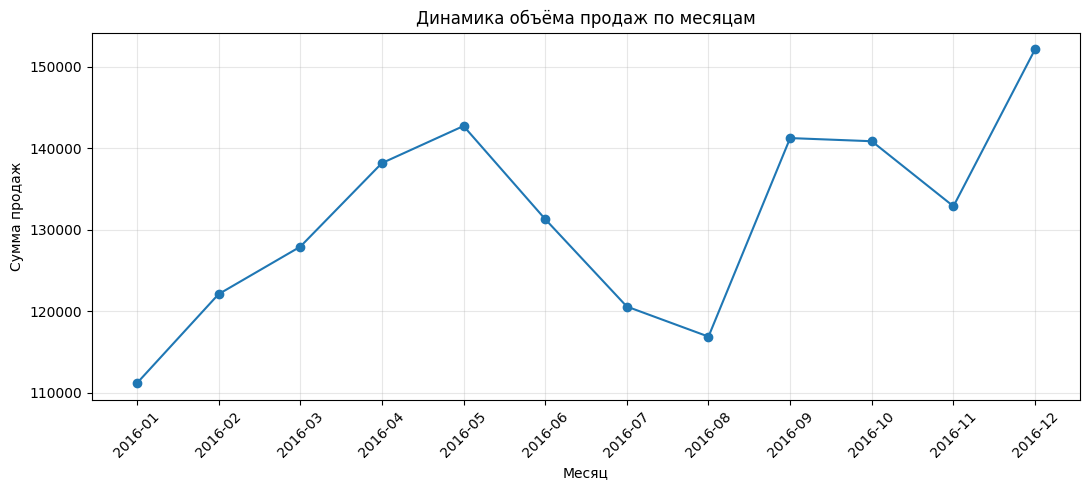

,Month,Sales
0,2016-01,"111,200.28"
1,2016-02,"122,114.61"
2,2016-03,"127,924.54"
3,2016-04,"138,172.11"
4,2016-05,"142,719.86"
5,2016-06,"131,305.35"
6,2016-07,"120,591.97"
7,2016-08,"116,908.98"
8,2016-09,"141,239.89"
9,2016-10,"140,853.51"


In [10]:
monthly_sales = (
    df.groupby('Month', as_index=False)
      .agg(Sales=('Sales_Amount', 'sum'))
      .sort_values('Month')
)

plt.figure(figsize=(11, 5))
plt.plot(monthly_sales['Month'], monthly_sales['Sales'], marker='o')
plt.title('Динамика объёма продаж по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Сумма продаж')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_sales)

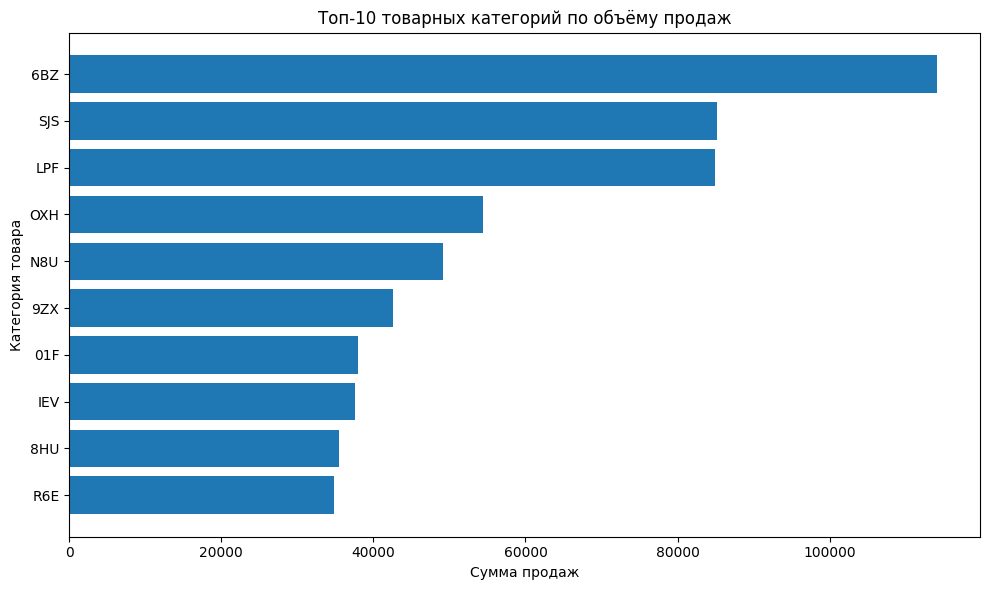

,SKU_Category,Sales
30,6BZ,"114,061.33"
155,SJS,"85,142.31"
106,LPF,"84,921.91"
131,OXH,"54,470.16"
119,N8U,"49,119.55"
41,9ZX,"42,629.31"
0,01F,"38,029.87"
91,IEV,"37,618.22"
38,8HU,"35,528.14"
148,R6E,"34,784.59"


In [11]:
category_sales = (
    df.groupby('SKU_Category', as_index=False)
      .agg(Sales=('Sales_Amount', 'sum'))
      .sort_values('Sales', ascending=False)
      .head(10)
      .sort_values('Sales')
)

plt.figure(figsize=(10, 6))
plt.barh(category_sales['SKU_Category'], category_sales['Sales'])
plt.title('Топ-10 товарных категорий по объёму продаж')
plt.xlabel('Сумма продаж')
plt.ylabel('Категория товара')
plt.tight_layout()
plt.show()

display(category_sales.sort_values('Sales', ascending=False))

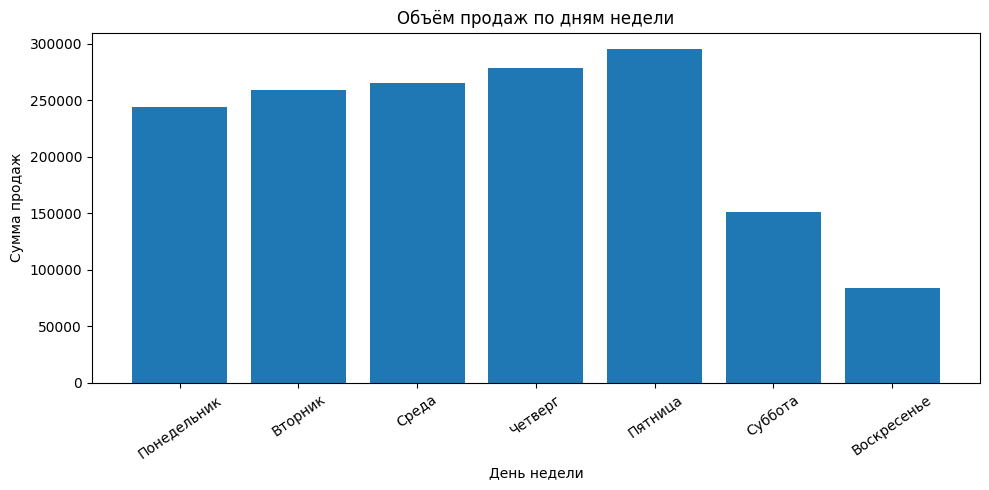

,Weekday,Sales,Transactions
0,Понедельник,"244,476.14",9851
1,Вторник,"258,970.92",9832
2,Среда,"265,012.30",9969
3,Четверг,"278,393.42",10878
4,Пятница,"295,344.35",11211
5,Суббота,"151,538.78",7731
6,Воскресенье,"84,302.71",5210


In [12]:
weekday_order = ['Понедельник', 'Вторник', 'Среда', 'Четверг',
                 'Пятница', 'Суббота', 'Воскресенье']

weekday_sales = (
    df.groupby('Weekday', as_index=False)
      .agg(Sales=('Sales_Amount', 'sum'),
           Transactions=('Transaction_ID', 'nunique'))
      .set_index('Weekday')
      .reindex(weekday_order)
      .reset_index()
)

plt.figure(figsize=(10, 5))
plt.bar(weekday_sales['Weekday'], weekday_sales['Sales'])
plt.title('Объём продаж по дням недели')
plt.xlabel('День недели')
plt.ylabel('Сумма продаж')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

display(weekday_sales)

### Интерпретация визуального анализа

По исходным данным можно определить масштаб продаж, наиболее значимые товарные категории, месяцы с повышенным объёмом реализации и различия активности по дням недели. Эти результаты могут быть использованы для планирования запасов, настройки маркетинговых предложений и контроля продаж по ассортиментным группам.


## 6. Подготовка данных для отчёта в Yandex DataLens

Yandex DataLens является отдельной облачной BI-системой и не запускается внутри Google Colab. Но в ноутбуке формируется готовый очищенный файл, который можно загрузить в DataLens как источник данных.

Для дашборда целесообразно построить:
1. индикаторы: сумма продаж, число транзакций, число покупателей;
2. линейный график продаж по месяцам;
3. столбчатую диаграмму продаж по категориям;
4. таблицу или тепловой срез «месяц × категория товара».


In [13]:
datalens_data = df.copy()
datalens_data['Date'] = datalens_data['Date'].dt.strftime('%Y-%m-%d')
datalens_data.to_csv('datalens_scanner_prepared.csv',
                     index=False,
                     encoding='utf-8-sig')

print('Файл datalens_scanner_prepared.csv подготовлен для загрузки в DataLens.')
print(f'Строк в экспортированном файле: {len(datalens_data):,}')

Файл datalens_scanner_prepared.csv подготовлен для загрузки в DataLens.
Строк в экспортированном файле: 131,706


## 7. Кластеризация покупателей

Кластеризация выполняется не по отдельным строкам покупок, а по покупателям. Такой подход содержательно оправдан: бизнесу важнее выделить группы клиентов с разной ценностью и активностью, чем разделять отдельные товарные позиции.

Для каждого покупателя рассчитываются признаки:
- общая сумма покупок;
- количество транзакций;
- количество купленных единиц;
- средний чек;
- число товарных категорий;
- число дней с момента последней покупки.

Перед кластеризацией показатели логарифмируются и стандартизируются, поскольку они имеют разные масштабы измерения и выраженную асимметрию распределения.


In [14]:
receipts = (
    df.groupby(['Customer_ID', 'Transaction_ID'], as_index=False)
      .agg(Check_Amount=('Sales_Amount', 'sum'))
)

avg_receipt = (
    receipts.groupby('Customer_ID')['Check_Amount']
            .mean()
            .rename('Avg_Receipt')
)

analysis_date = df['Date'].max() + pd.Timedelta(days=1)

customers = (
    df.groupby('Customer_ID')
      .agg(Total_Sales=('Sales_Amount', 'sum'),
           Transactions=('Transaction_ID', 'nunique'),
           Items=('Quantity', 'sum'),
           Unique_Categories=('SKU_Category', 'nunique'),
           Last_Purchase=('Date', 'max'))
      .join(avg_receipt)
      .reset_index()
)

customers['Recency_Days'] = (analysis_date - customers['Last_Purchase']).dt.days

features = [
    'Total_Sales', 'Transactions', 'Items',
    'Avg_Receipt', 'Unique_Categories', 'Recency_Days'
]

display(customers[features].describe().round(2))

,Total_Sales,Transactions,Items,Avg_Receipt,Unique_Categories,Recency_Days
count,"22,625.00","22,625.00","22,625.00","22,625.00","22,625.00","22,625.00"
mean,69.75,2.86,8.65,21.76,3.88,162.10
std,152.31,4.00,20.98,28.35,4.10,115.92
min,0.14,1.00,0.33,0.14,1.00,1.00
25%,10.17,1.00,2.00,7.75,1.00,48.00
50%,23.85,1.00,3.00,13.44,2.00,150.00
75%,63.07,3.00,8.00,24.49,5.00,272.00
max,"3,985.94",99.00,814.90,544.79,65.00,365.00


,Количество кластеров,Инерция,Silhouette score
0,2,"73,888.81",0.43
1,3,"56,891.02",0.31
2,4,"49,603.33",0.31
3,5,"43,329.13",0.26
4,6,"39,221.79",0.25


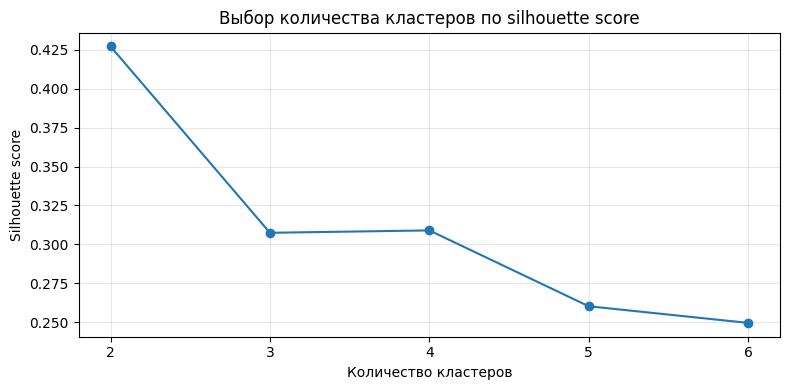

In [15]:
X = np.log1p(customers[features])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

evaluation = []

with threadpool_limits(limits=1):
    for k in range(2, 7):
        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=42,
            n_init=10,
            batch_size=2048,
            max_iter=100
        )
        labels = model.fit_predict(X_scaled)
        score = silhouette_score(
            X_scaled,
            labels,
            sample_size=min(3000, len(customers)),
            random_state=42
        )
        evaluation.append({
            'Количество кластеров': k,
            'Инерция': model.inertia_,
            'Silhouette score': score
        })

evaluation_df = pd.DataFrame(evaluation)
display(evaluation_df.round(4))

plt.figure(figsize=(8, 4))
plt.plot(evaluation_df['Количество кластеров'],
         evaluation_df['Silhouette score'],
         marker='o')
plt.title('Выбор количества кластеров по silhouette score')
plt.xlabel('Количество кластеров')
plt.ylabel('Silhouette score')
plt.xticks(evaluation_df['Количество кластеров'])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
best_k = int(
    evaluation_df.loc[
        evaluation_df['Silhouette score'].idxmax(),
        'Количество кластеров'
    ]
)

with threadpool_limits(limits=1):
    final_model = MiniBatchKMeans(
        n_clusters=best_k,
        random_state=42,
        n_init=10,
        batch_size=2048,
        max_iter=100
    )
    customers['Cluster'] = final_model.fit_predict(X_scaled)

profile = (
    customers.groupby('Cluster')
             .agg(
                 Customers=('Customer_ID', 'count'),
                 Total_Sales=('Total_Sales', 'sum'),
                 Avg_Sales_Per_Customer=('Total_Sales', 'mean'),
                 Median_Sales=('Total_Sales', 'median'),
                 Avg_Transactions=('Transactions', 'mean'),
                 Avg_Receipt=('Avg_Receipt', 'mean'),
                 Avg_Items=('Items', 'mean'),
                 Avg_Categories=('Unique_Categories', 'mean'),
                 Avg_Recency_Days=('Recency_Days', 'mean')
             )
)

profile['Sales_Share_Pct'] = (
    profile['Total_Sales'] / customers['Total_Sales'].sum() * 100
)
profile['Customer_Share_Pct'] = (
    profile['Customers'] / len(customers) * 100
)

ordered_clusters = (
    profile['Avg_Sales_Per_Customer']
    .sort_values(ascending=False)
    .index
    .tolist()
)

segment_names = {}
for position, cluster in enumerate(ordered_clusters):
    if position == 0:
        segment_names[cluster] = 'Высокая ценность'
    elif position == len(ordered_clusters) - 1:
        segment_names[cluster] = 'Низкая активность'
    else:
        segment_names[cluster] = f'Средний сегмент {position}'

customers['Segment'] = customers['Cluster'].map(segment_names)
profile['Segment'] = profile.index.map(segment_names)

profile_display = (
    profile.reset_index()
           .sort_values('Avg_Sales_Per_Customer', ascending=False)
)

print(f'Оптимальное число кластеров по silhouette score: {best_k}')
display(profile_display.round(2))

Оптимальное число кластеров по silhouette score: 2


,Cluster,Customers,Total_Sales,Avg_Sales_Per_Customer,Median_Sales,Avg_Transactions,Avg_Receipt,Avg_Items,Avg_Categories,Avg_Recency_Days,Sales_Share_Pct,Customer_Share_Pct,Segment
0,0,7020,"1,276,705.72",181.87,103.67,6.12,36.94,21.97,8.21,108.85,80.90,31.03,Высокая ценность
1,1,15605,"301,332.90",19.31,14.04,1.39,14.93,2.65,1.93,186.05,19.10,68.97,Низкая активность


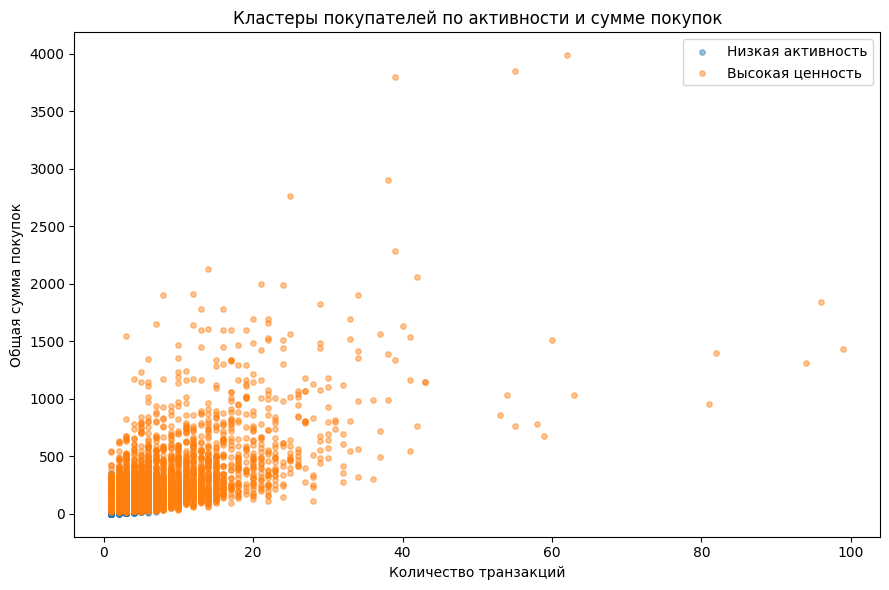

In [17]:
plt.figure(figsize=(9, 6))
for segment in customers['Segment'].unique():
    subset = customers[customers['Segment'] == segment]
    plt.scatter(
        subset['Transactions'],
        subset['Total_Sales'],
        label=segment,
        alpha=0.45,
        s=15
    )

plt.title('Кластеры покупателей по активности и сумме покупок')
plt.xlabel('Количество транзакций')
plt.ylabel('Общая сумма покупок')
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
customers_export = customers.copy()
customers_export['Last_Purchase'] = customers_export['Last_Purchase'].dt.strftime('%Y-%m-%d')
customers_export.to_csv('customer_clusters.csv',
                        index=False,
                        encoding='utf-8-sig')

best_segment = profile_display.iloc[0]
base_segment = profile_display.iloc[-1]

print('Интерпретация кластеров:')
print(
    f"- Сегмент «{best_segment['Segment']}» включает "
    f"{int(best_segment['Customers']):,} покупателей "
    f"({best_segment['Customer_Share_Pct']:.2f}% клиентской базы) "
    f"и обеспечивает {best_segment['Sales_Share_Pct']:.2f}% продаж."
)
print(
    f"- Сегмент «{base_segment['Segment']}» включает "
    f"{int(base_segment['Customers']):,} покупателей "
    f"({base_segment['Customer_Share_Pct']:.2f}% клиентской базы) "
    f"и обеспечивает {base_segment['Sales_Share_Pct']:.2f}% продаж."
)
print(
    "- Для клиентов высокой ценности целесообразны программы удержания "
    "и персональные предложения, а для малоактивного сегмента — "
    "стимулирующие повторную покупку коммуникации."
)
print('Файл customer_clusters.csv подготовлен для выгрузки.')

Интерпретация кластеров:
- Сегмент «Высокая ценность» включает 7,020 покупателей (31.03% клиентской базы) и обеспечивает 80.90% продаж.
- Сегмент «Низкая активность» включает 15,605 покупателей (68.97% клиентской базы) и обеспечивает 19.10% продаж.
- Для клиентов высокой ценности целесообразны программы удержания и персональные предложения, а для малоактивного сегмента — стимулирующие повторную покупку коммуникации.
Файл customer_clusters.csv подготовлен для выгрузки.


## 8. Итоговые выводы

По результатам анализа набора `scanner_data.csv` установлено следующее.

1. Набор содержит данные о продажах розничного магазина и подходит для аналитического проекта, поскольку объединяет количественные и категориальные показатели.
2. Технический индексный столбец исключён из анализа. В предоставленной версии файла пропущенных значений не выявлено, поэтому необоснованное восстановление данных не проводилось.
3. Для анализа рассчитана цена единицы товара `Price`, а из даты получены временные признаки, необходимые для построения срезов.
4. Выполнены аналитические срезы по месяцам, категориям товаров и дням недели; сформирован файл для построения отчёта в Yandex DataLens.
5. Кластеризация проведена на уровне покупателей по показателям их активности и ценности. Полученные сегменты позволяют различать клиентов с высоким вкладом в продажи и клиентов с невысокой покупательской активностью.
6. Практическая ценность анализа состоит в возможности применять разные маркетинговые решения к разным группам покупателей и учитывать структуру продаж при планировании ассортимента и коммуникаций.


## 9. Скачивание подготовленных файлов

После выполнения всего ноутбука запустите следующую ячейку, чтобы скачать подготовленные CSV-файлы из Google Colab.

In [19]:
try:
    from google.colab import files
    files.download('datalens_scanner_prepared.csv')
    files.download('customer_clusters.csv')
except ImportError:
    print('Файлы сохранены в текущей рабочей папке ноутбука:')
    print('- datalens_scanner_prepared.csv')
    print('- customer_clusters.csv')

Файлы сохранены в текущей рабочей папке ноутбука:
- datalens_scanner_prepared.csv
- customer_clusters.csv
